# Demo

A: SIFT + ratio test. B: SIFT + LightGlue. C: SuperPoint + LightGlue.

Workflow: **preview data → reuse or select best train parameters → compare train results → reuse or generate test results → visualize test matches → compare test results**. All figures display inline. Running all cells may launch parameter search or evaluation when required files are missing or invalid.


## 0. Setup

Clone the project if needed, then install it into the current notebook environment even when the project folder already exists. Refresh package paths and verify LightGlue before continuing. Device detection is in the next section.


In [36]:
from pathlib import Path

if Path.cwd().name != "CS-117-Final-Project":
    !git clone --quiet https://github.com/StevenZBX/CS-117-Final-Project
    %cd CS-117-Final-Project

# Always install, even when the project folder already exists.
%pip install --progress-bar off --quiet -e .

import lightglue


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Preview the data

Select one illumination and one viewpoint sequence from train and display all six images in each sequence. No models are loaded yet. Train contains 96 sequences; test contains 20 different sequences. Device selection prefers CUDA, then MPS, then CPU.


Device: mps | Train: 96 sequences | Test: 20 sequences


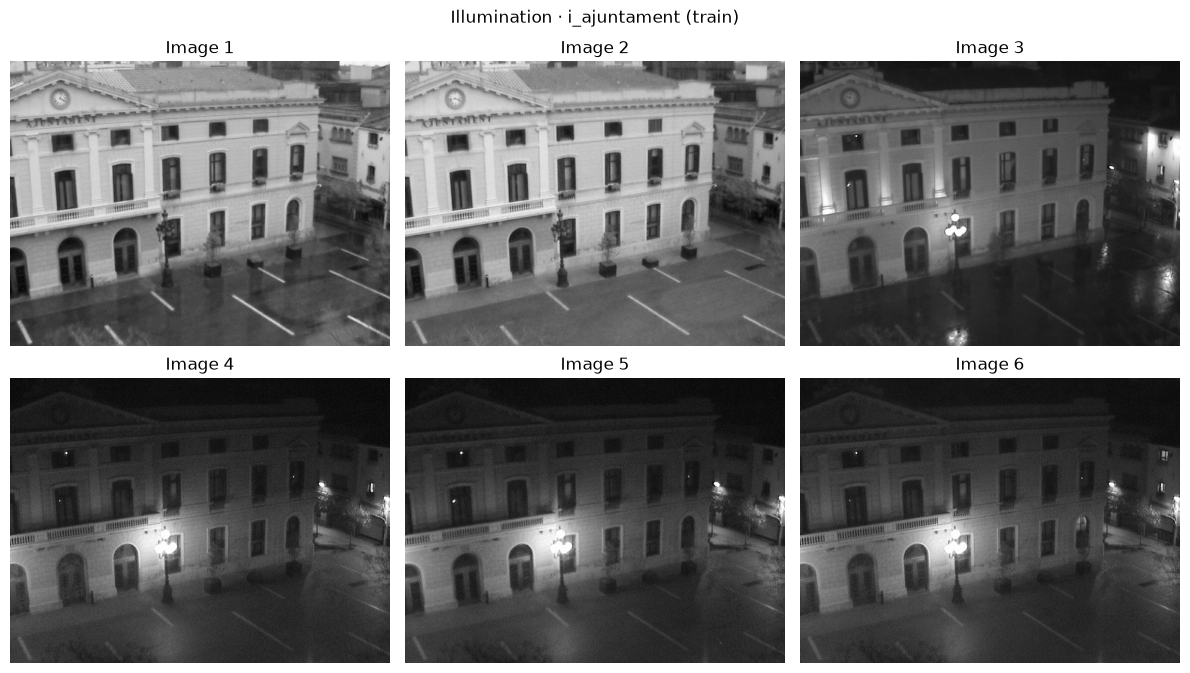

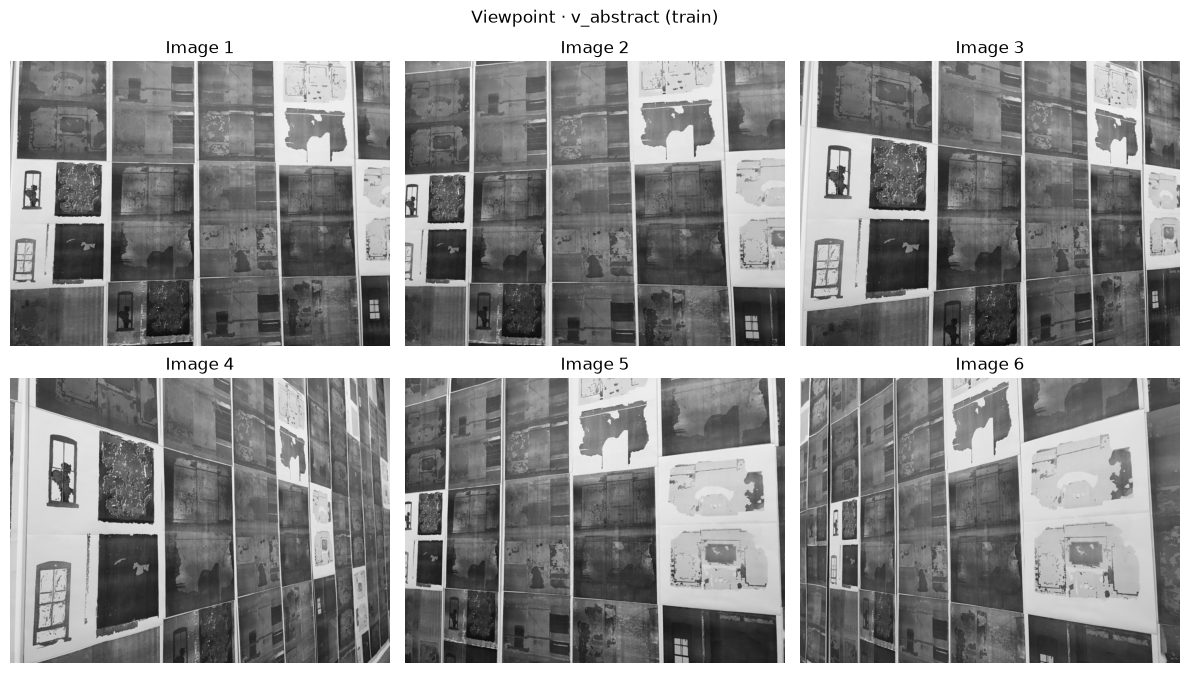

In [ ]:
import sys, json, subprocess
from pathlib import Path
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython

PROJECT_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from dataset_load import get_data_root, load_image, score, validate_splits
from evaluate import (build_backends, match_points, LABELS, read_results, plot_results,
                      validate_results, load_best_config, run_pairs, write_results)

get_ipython().run_line_magic("matplotlib", "inline")
METHODS = ["A", "B", "C"]
TARGET_INDEX, DISPLAY_LIMIT = 5, 150
CONFIG_PATH = PROJECT_ROOT / "configs/experiment.json"
CONFIG = json.loads(CONFIG_PATH.read_text())
DATA, RESULTS = get_data_root(), PROJECT_ROOT / "results"
PARAMETERS, CACHE = PROJECT_ROOT / "configs/best_parameters", PROJECT_ROOT / "data/feature_cache"
mps = getattr(torch.backends, "mps", None)
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if mps is not None and mps.is_available() else "cpu"
cv2.setNumThreads(CONFIG["opencv_threads"])
cv2.setRNGSeed(0)
train_ids, _ = validate_splits(DATA, "train")
test_ids, _ = validate_splits(DATA, "test")
DATA_SEQUENCES = [next(s for s in train_ids if s.startswith(prefix)) for prefix in ("i_", "v_")]
print(f"Device: {DEVICE} | Train: {len(train_ids)} sequences | Test: {len(test_ids)} sequences")

for sequence in DATA_SEQUENCES:
    fig, axes = plt.subplots(2, 3, figsize=(12, 7))
    for index, ax in enumerate(axes.flat, start=1):
        image, _ = load_image(DATA / sequence / f"{index}.ppm", CONFIG["max_side"])
        ax.imshow(image, cmap="gray")
        ax.set_title(f"Image {index}")
        ax.axis("off")
    category = "Illumination" if sequence.startswith("i_") else "Viewpoint"
    fig.suptitle(f"{category} · {sequence} (train)")
    fig.tight_layout()
    display(fig)
    plt.close(fig)

## 2. Train or load the best parameters

For each selected method, load its saved best parameters if they match the current configuration and train manifest. Otherwise run `train.py` for that method, using only train data. Here “training” means selecting matching parameters for pretrained models.

If valid parameters exist but their train CSV is missing/invalid, regenerate only the train scores with those parameters; do not repeat the parameter search. Existing complete train CSVs are reused. Only methods needing work are run.


In [38]:
def read_split_results(method, split, ids):
    path = RESULTS / f"{split}_{method}.csv"
    expected = {(sequence, k) for sequence in ids for k in range(2, 7)}
    try:
        rows = read_results(path)
        validate_results({method: rows})
        if len(rows) != len(expected) or {(row["sequence"], row["k"]) for row in rows} != expected:
            raise ValueError("CSV does not match the current split")
        return rows
    except (OSError, ValueError, KeyError, TypeError) as error:
        print(f"{path.name}: {error}")
        return None


def run_script(script, methods):
    subprocess.check_call([
        sys.executable, "-u", str(PROJECT_ROOT / "scripts" / script),
        "--methods", *methods, "--device", DEVICE,
        "--data", str(DATA), "--config", str(CONFIG_PATH),
        "--cache", str(CACHE), "--output", str(RESULTS),
        "--parameters", str(PARAMETERS),
    ], cwd=str(PROJECT_ROOT))


best_configs, train_results = {}, {}
retrained_methods = []
for method in METHODS:
    try:
        best_configs[method] = load_best_config(method, CONFIG, PARAMETERS)
    except (OSError, ValueError, KeyError) as error:
        print(f"{method}: {error} Running parameter search on train.")
        run_script("train.py", [method])
        best_configs[method] = load_best_config(method, CONFIG, PARAMETERS)
        retrained_methods.append(method)
    rows = read_split_results(method, "train", train_ids)
    if rows is None:
        print(f"{method}: regenerating train scores with saved best parameters.")
        rows = run_pairs(method, best_configs[method], DATA, train_ids, CACHE, DEVICE)
        write_results(RESULTS / f"train_{method}.csv", rows)
    train_results[method] = rows

A: saved ratio=0.7, train MMA@3=0.861646
B: saved filter_threshold=0.3, train MMA@3=0.915658
C: saved filter_threshold=0.3, train MMA@3=0.865816


### Train comparison

Compare the selected best candidates across all 96 train sequences / 480 pairs. These results were used for parameter selection and are separate from test performance.


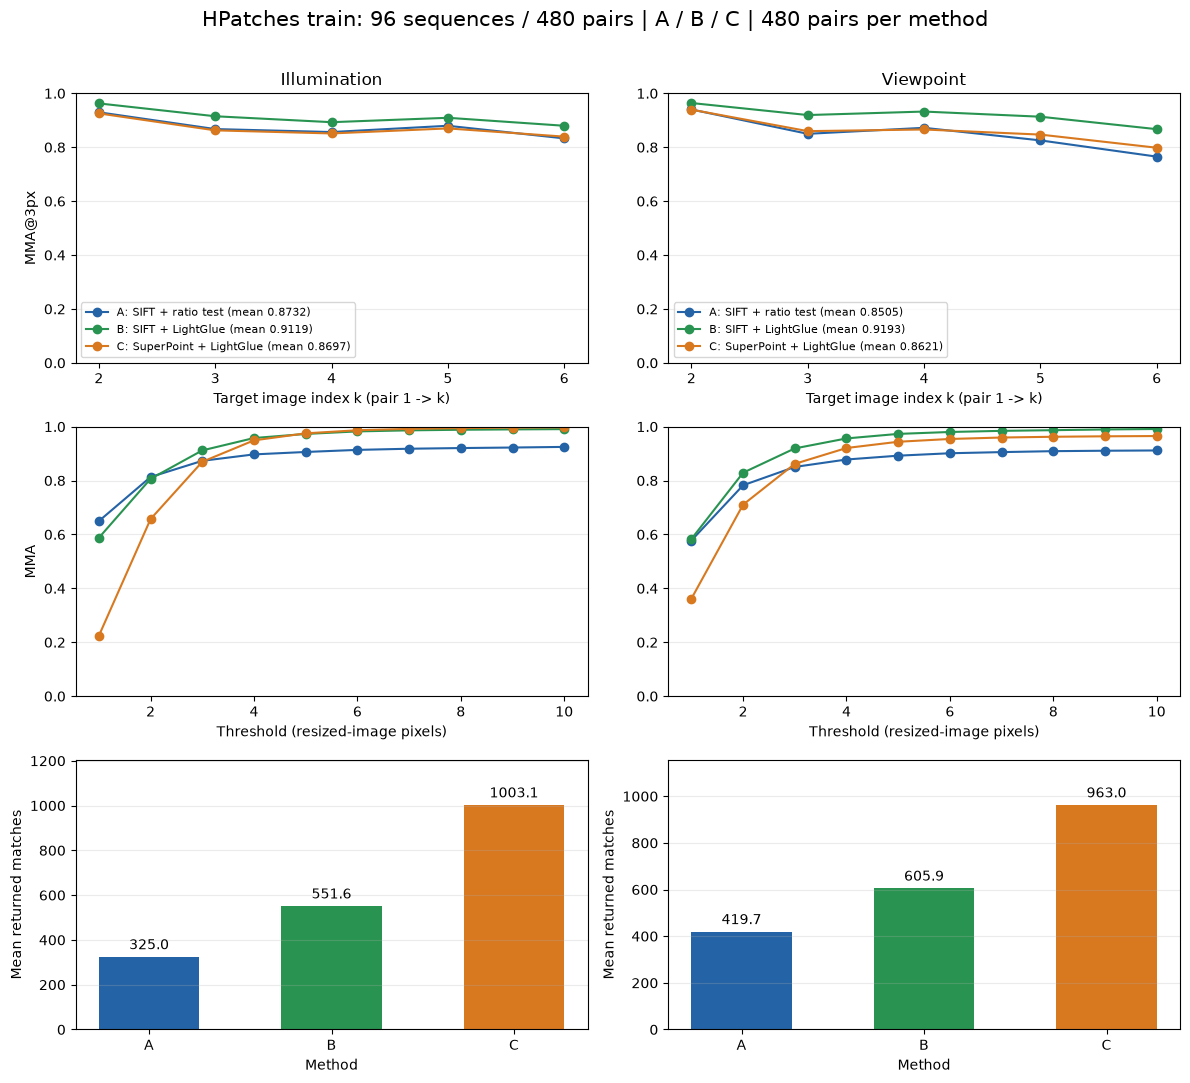

In [39]:
fig = plot_results(train_results, split="train: 96 sequences / 480 pairs")
display(fig)
plt.close(fig)


## 3. Test performance

Reuse each method's valid test CSV. If a file is missing/invalid, run `evaluate.py` only for that method, using its saved best parameters and only the 20 test sequences. Methods whose parameters were reselected above are evaluated again so their old test results are not reused.


In [46]:
test_results, needs_test = {}, []
for method in METHODS:
    rows = None if method in retrained_methods else read_split_results(method, "test", test_ids)
    if rows is None:
        needs_test.append(method)
    else:
        test_results[method] = rows
if needs_test:
    run_script("evaluate.py", needs_test)
    for method in needs_test:
        rows = read_split_results(method, "test", test_ids)
        if rows is None:
            raise RuntimeError(f"{method}: evaluation did not produce valid test results")
        test_results[method] = rows
else:
    print("Test Completed")

Test Completed


### Matching visualization on test examples

Use one illumination and one viewpoint sequence from **test**, with the saved best parameters. Each method shows LightGlue-style match lines above its detected feature points. Lime lines represent returned matches; the MMA@3 annotation measures all matches, not just the display subset. Feature points are not a pruning map. No image files are saved.


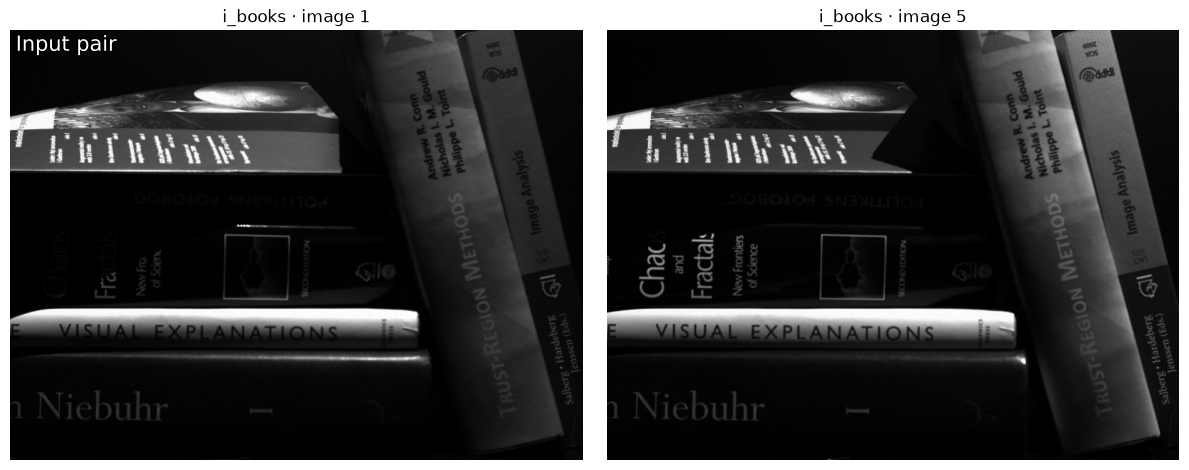

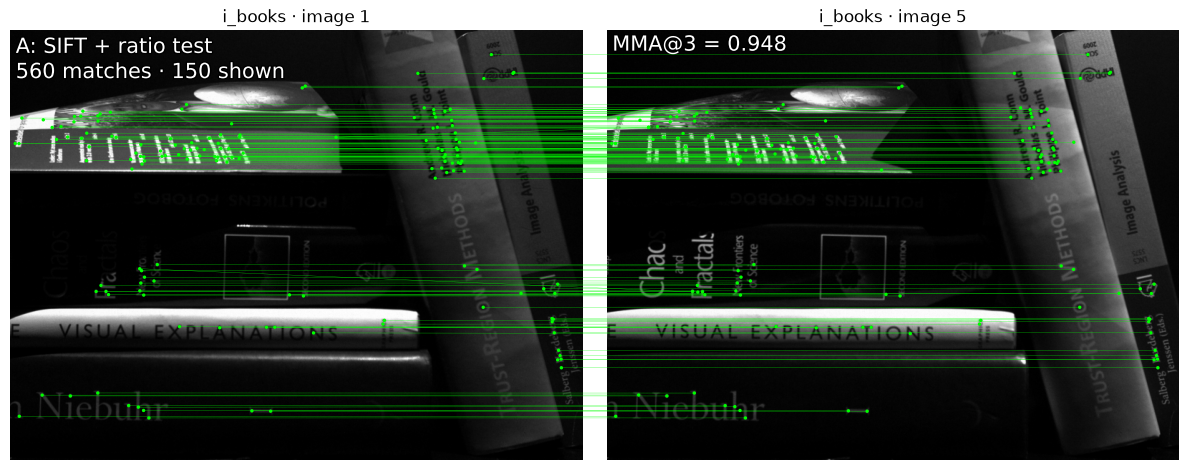

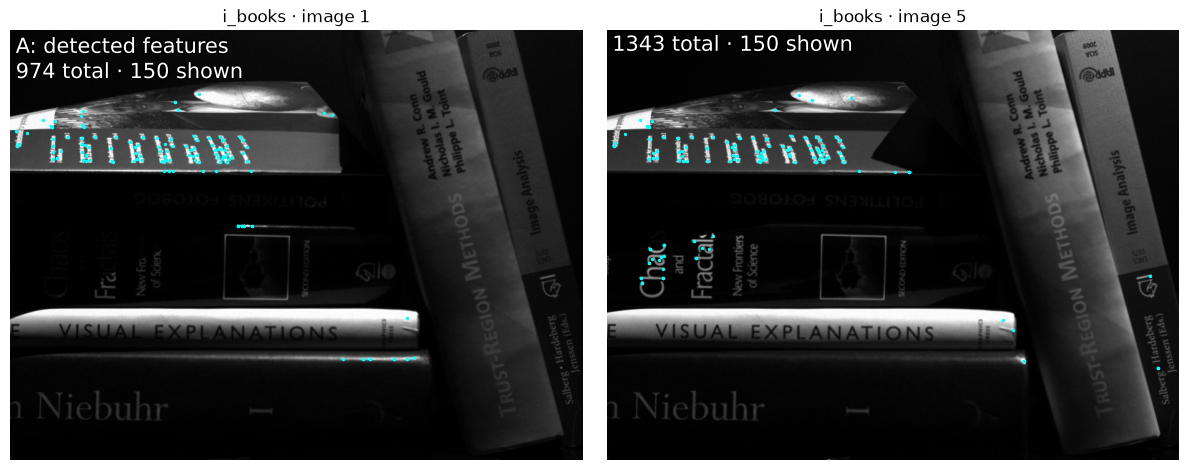

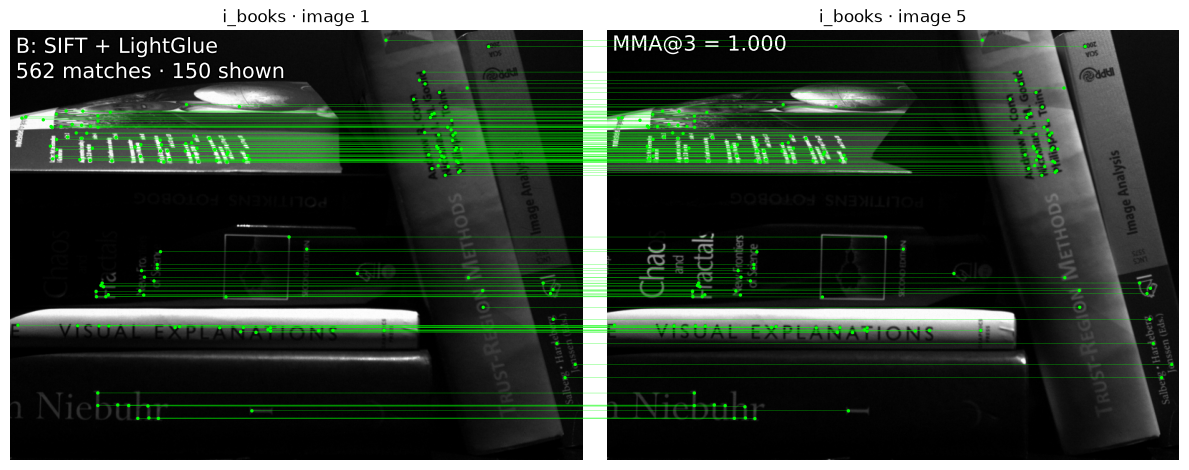

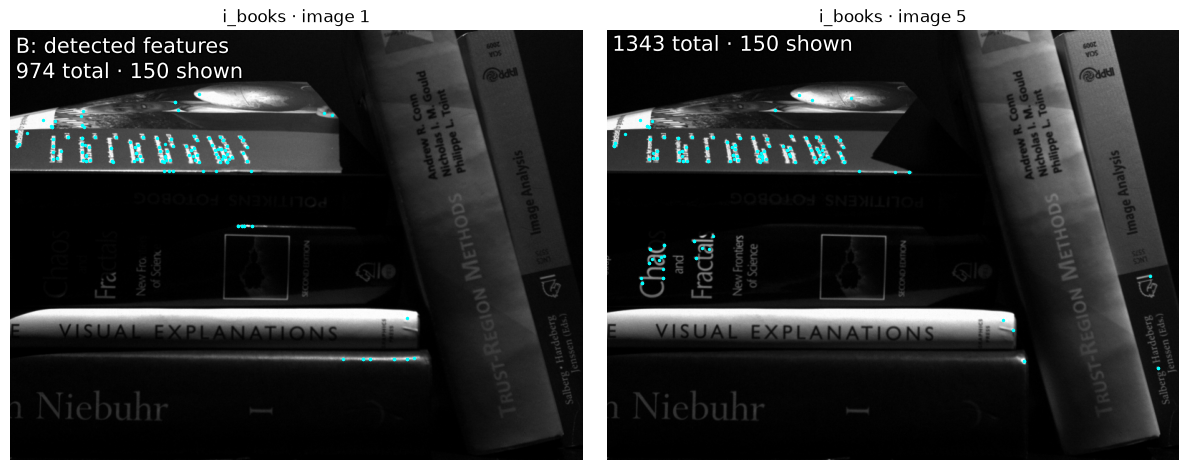

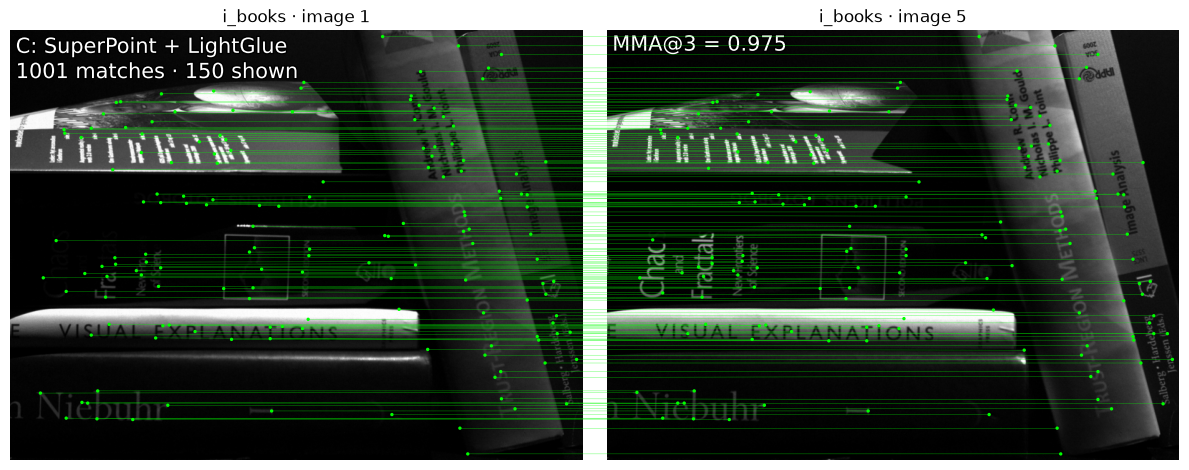

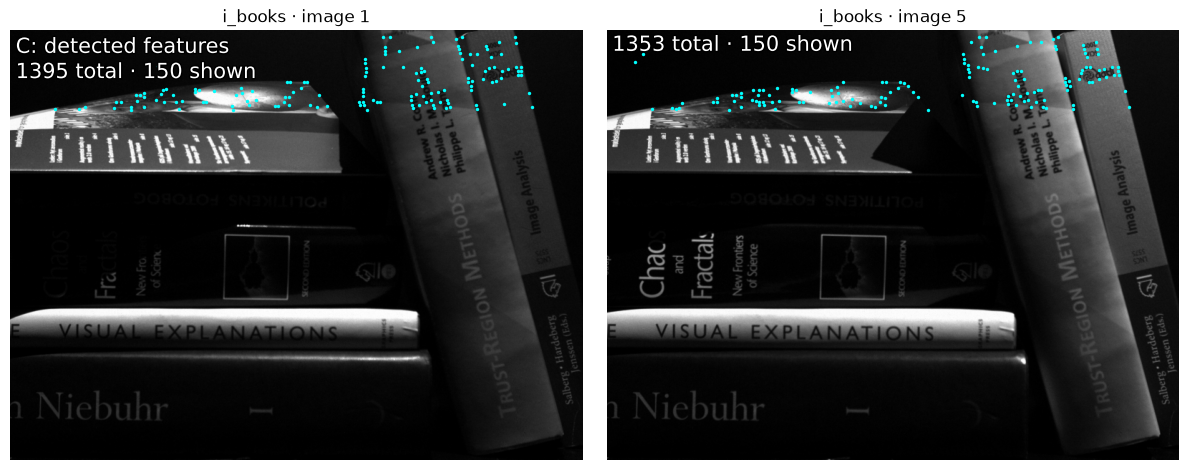

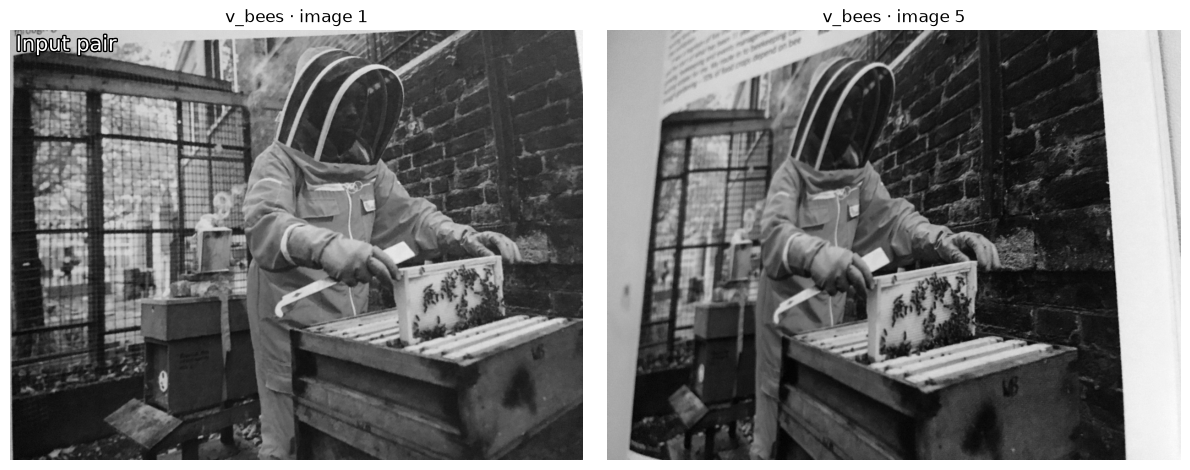

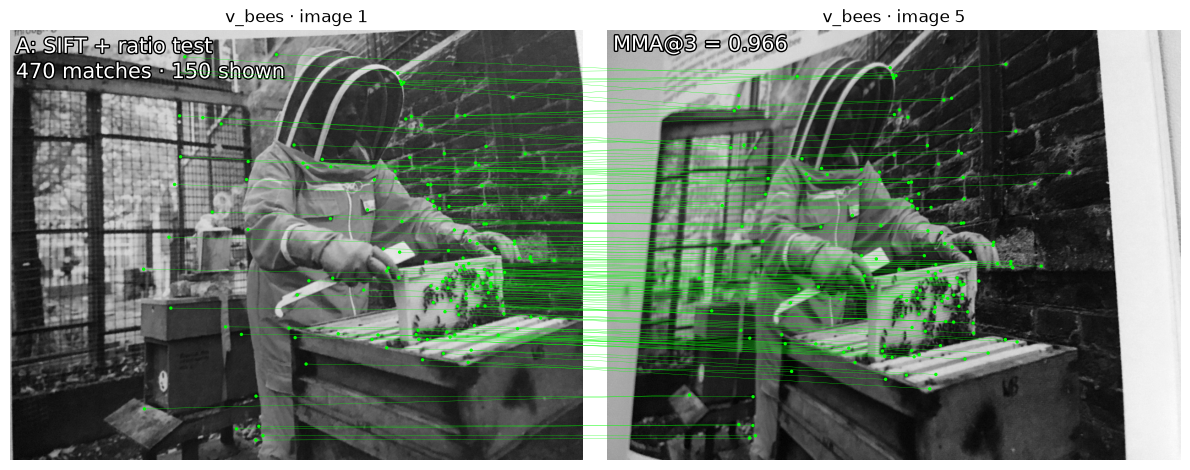

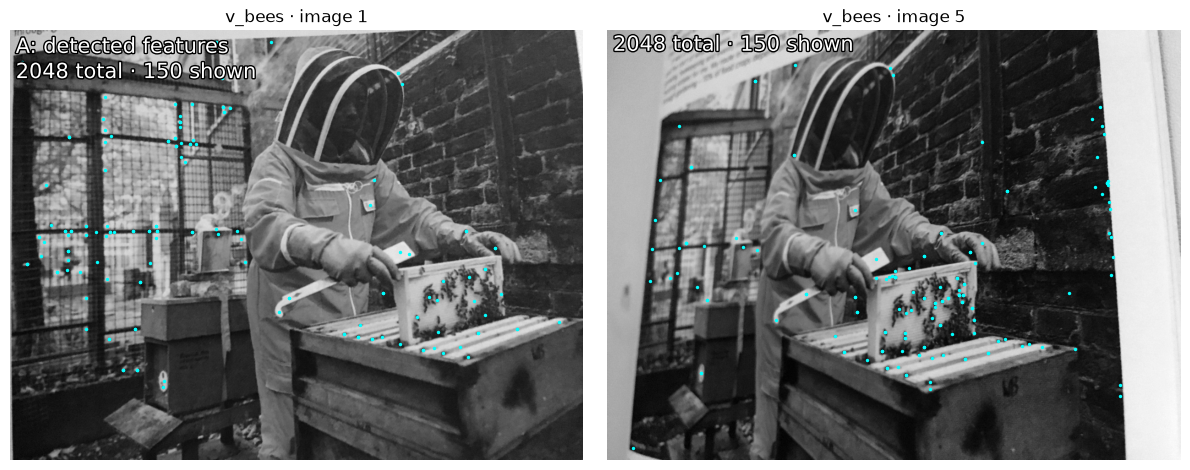

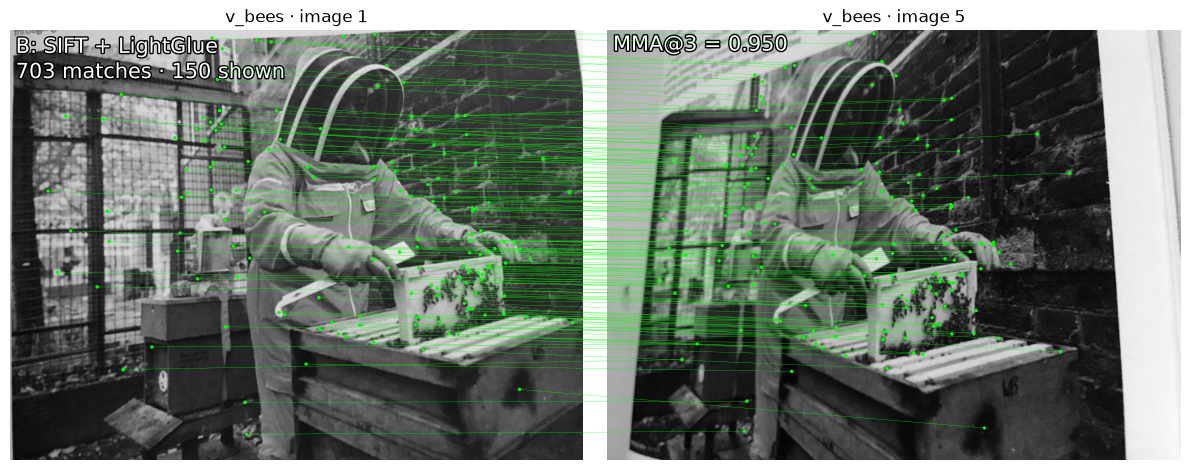

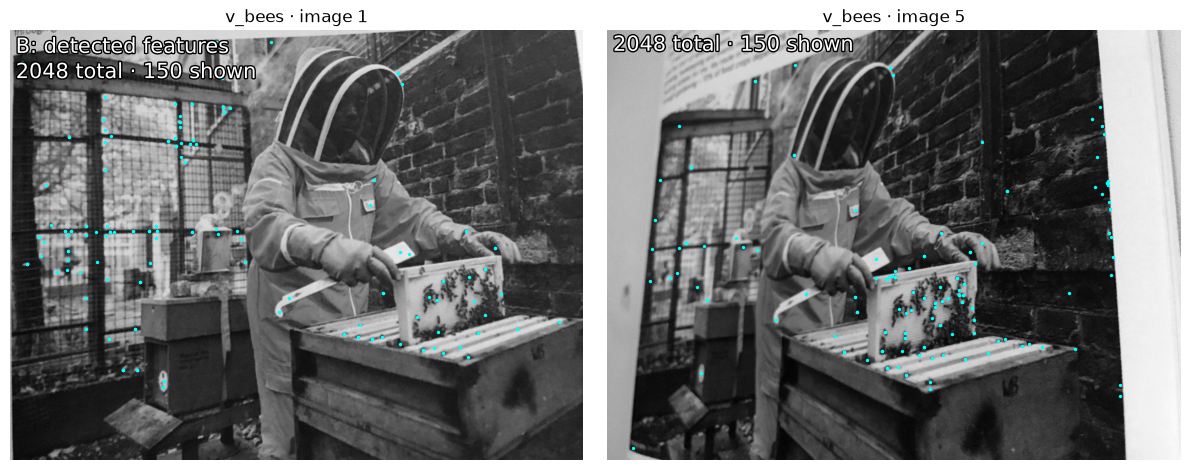

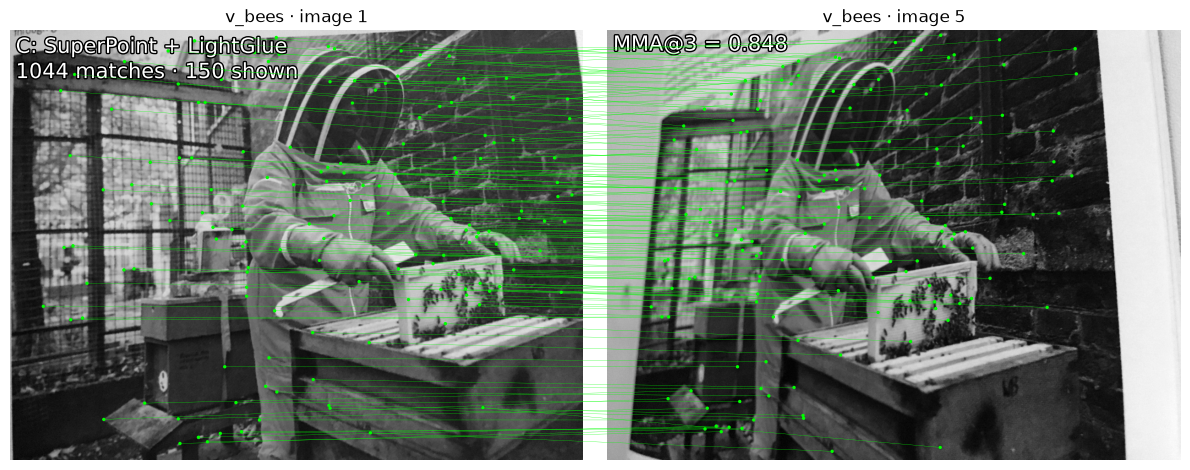

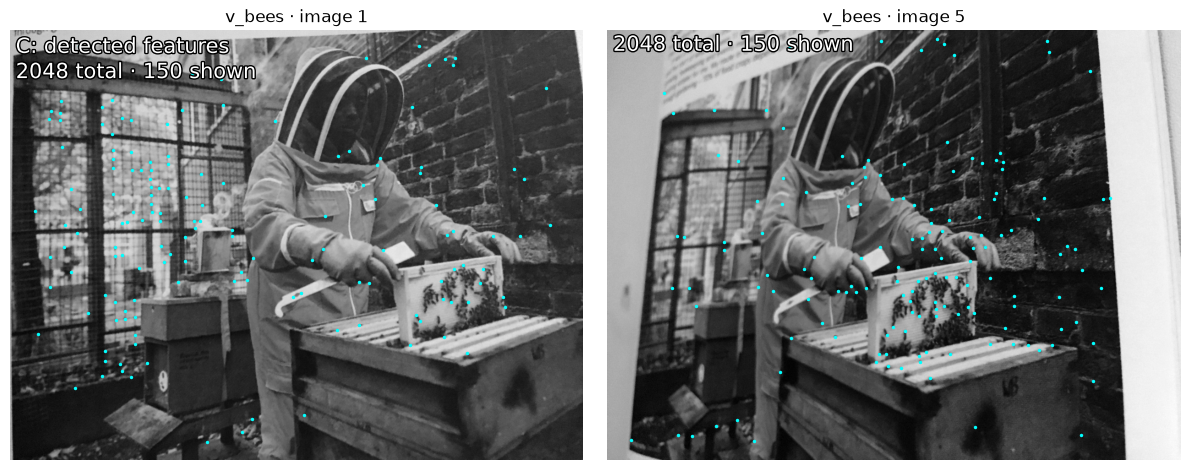

In [ ]:
TEST_SEQUENCES = [next(s for s in test_ids if s.startswith(prefix)) for prefix in ("i_", "v_")]
backends = build_backends(METHODS, CONFIG, CACHE, DEVICE, method_configs=best_configs)
from lightglue import viz2d
from dataset_load import load_pairs


def show_pair_demo(sequence, target_index):
    """LightGlue-style pair layout, using the project's matching interfaces."""
    image0, image1, H_resized = load_pairs(DATA / sequence, target_index, CONFIG["max_side"])
    titles = [f"{sequence} · image 1", f"{sequence} · image {target_index}"]

    # Input images appear side by side with independent axes and native aspect ratios.
    viz2d.plot_images([image0, image1], titles=titles)
    viz2d.add_text(0, "Input pair", fs=15)
    display(plt.gcf())
    plt.close(plt.gcf())

    for name, backend in backends.items():
        module, extractor, matcher, device = backend
        p0, p1 = match_points(backend, image0, image1)
        err = module.reprojection_error(p0, p1, H_resized)
        shown = np.linspace(0, len(p0) - 1, min(DISPLAY_LIMIT, len(p0)), dtype=int)

        # Match lines span the two axes, as in the upstream LightGlue demo.
        viz2d.plot_images([image0, image1], titles=titles)
        if len(shown):
            viz2d.plot_matches(p0[shown], p1[shown], color="lime", lw=0.2, ps=2)
        viz2d.add_text(0, f"{name}: {LABELS[name]}\n{len(p0)} matches · {len(shown)} shown", fs=15)
        viz2d.add_text(1, f"MMA@3 = {score(err, 3):.3f}", fs=15)
        display(plt.gcf())
        plt.close(plt.gcf())

        # Detected points below the match panel; this is not a pruning map.
        points0 = module.extract_keypoints(extractor, image0, device)
        points1 = module.extract_keypoints(extractor, image1, device)
        viz2d.plot_images([image0, image1], titles=titles)
        viz2d.plot_keypoints([points0[:DISPLAY_LIMIT], points1[:DISPLAY_LIMIT]], colors="cyan", ps=6)
        viz2d.add_text(0, f"{name}: detected features\n{len(points0)} total · {min(DISPLAY_LIMIT, len(points0))} shown", fs=15)
        viz2d.add_text(1, f"{len(points1)} total · {min(DISPLAY_LIMIT, len(points1))} shown", fs=15)
        display(plt.gcf())
        plt.close(plt.gcf())
        if hasattr(extractor, "clear_memory"):
            extractor.clear_memory()


for sequence in TEST_SEQUENCES:
    show_pair_demo(sequence, TARGET_INDEX)

# Full train/test jobs finish before loading these visualization models.
# Release them so rerunning the preparation cells does not retain GPU models.
backends.clear()
import gc
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()
elif DEVICE == "mps":
    torch.mps.empty_cache()

### Test comparison

Compare all selected methods on the same 20 test sequences / 100 pairs. Panels show MMA@3 by target image index, MMA across pixel thresholds, and mean match counts, separately for illumination and viewpoint.


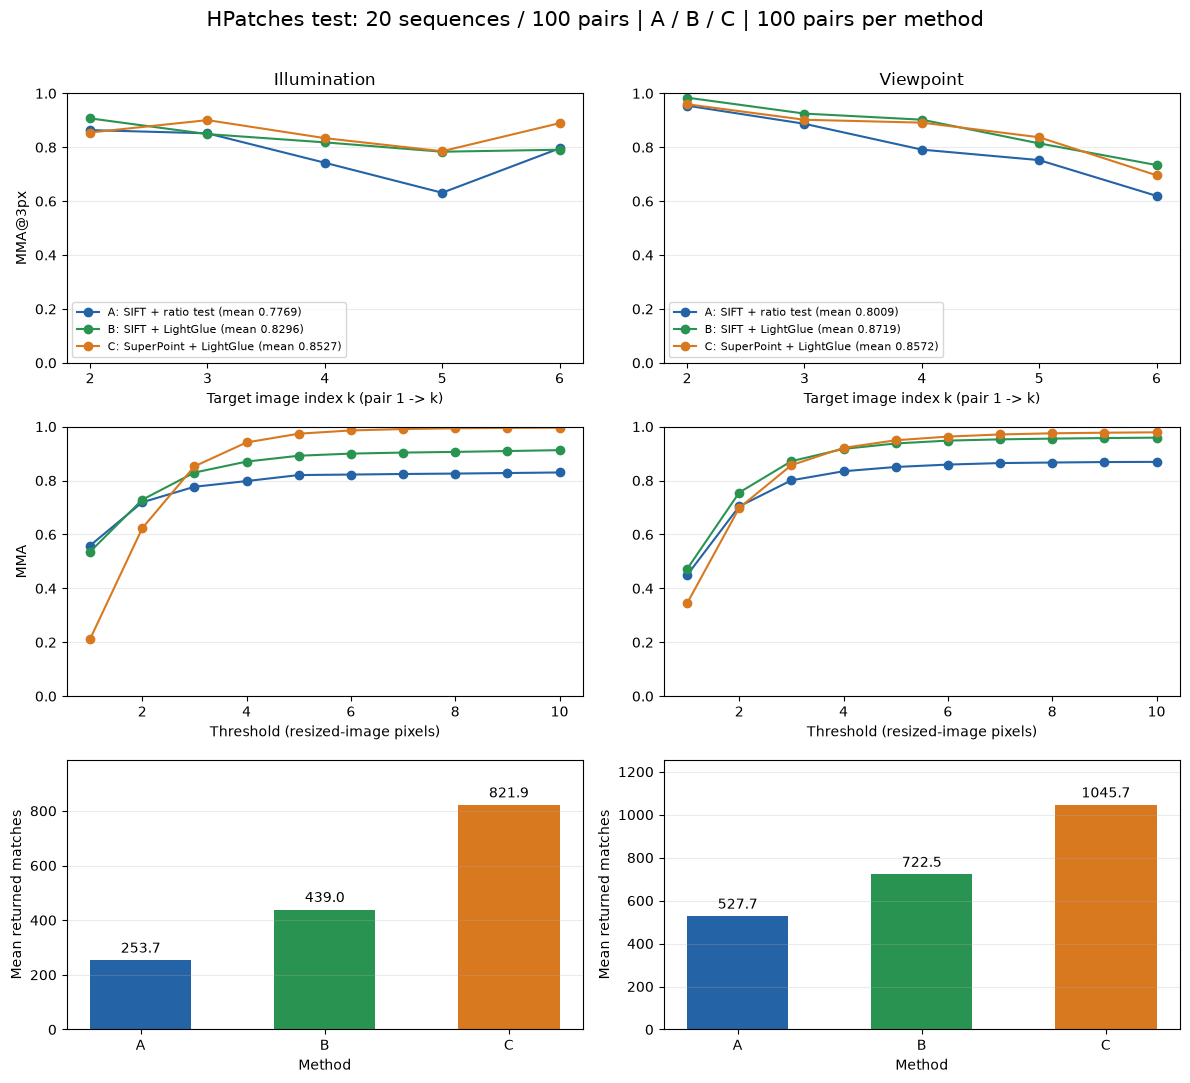

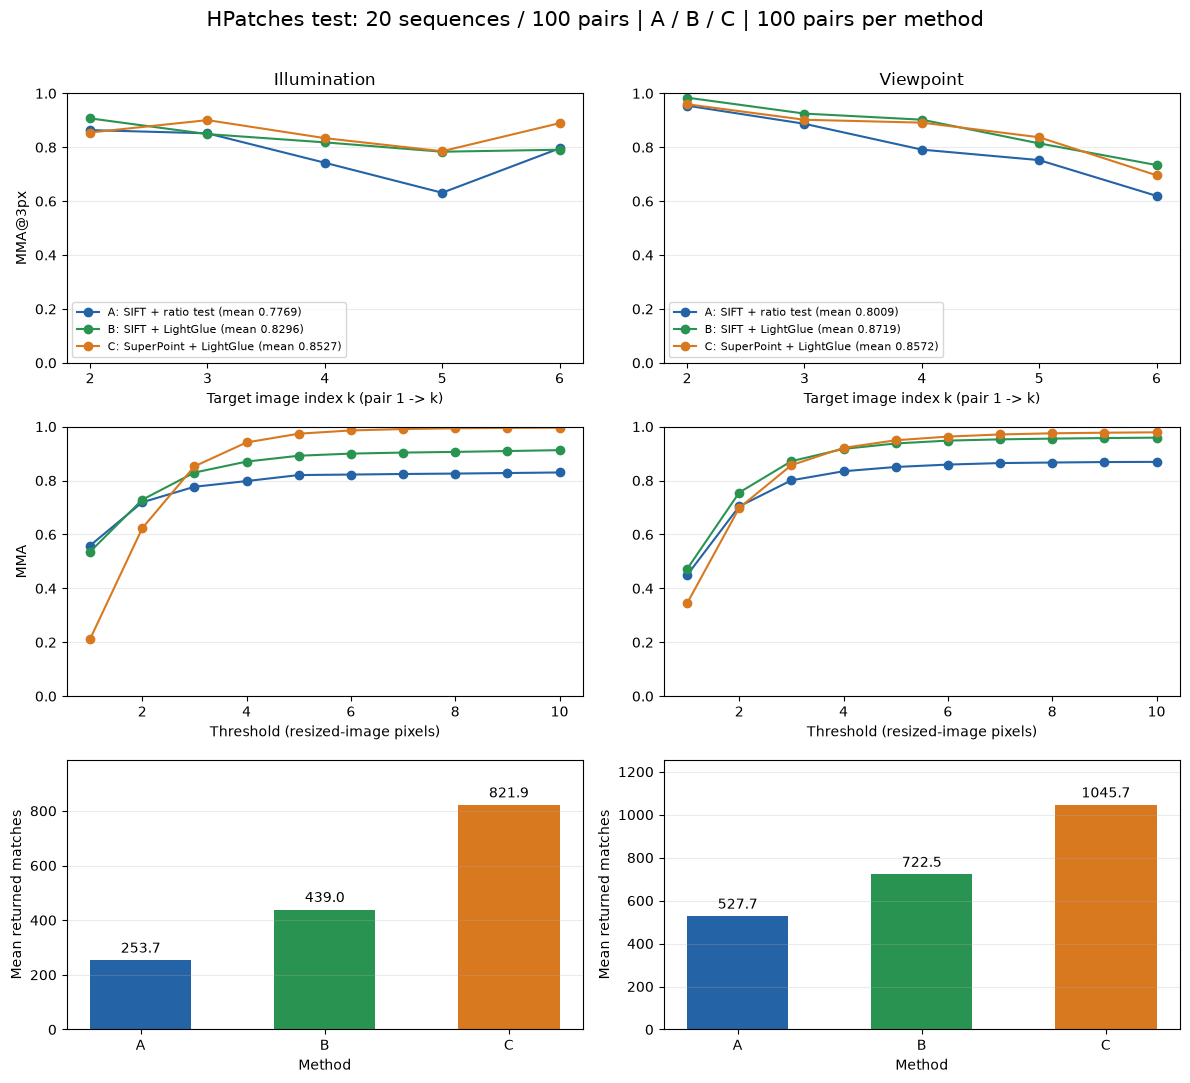

In [45]:
plot_results({method: test_results[method] for method in METHODS}, split="test: 20 sequences / 100 pairs")